# Sign-flipping with `osl-signflip`

Source reconstruction of M/EEG data can leave each parcel time course with an **arbitrary sign**. The sign depends
on how the source orientation and the parcel time course are estimated, so the same parcel can have opposite signs
in different recording sessions. Before combining sessions in a group-level analysis (e.g., functional connectivity
estimation or dynamic network models), these signs need to be aligned.

`osl-signflip` aligns the signs of every session to a common **template session**. For each session, it finds the
set of parcel flips (±1 per parcel) that makes the session's time-delay-embedded (TDE) covariance best match the
template's. It provides four methods for this:

| Method | `method` | Notes |
| :-- | :-- | :-- |
| Semidefinite programming relaxation | `"sdp"` (default) | Recommended. Seeded and insensitive to the seed. |
| Spectral synchronisation | `"spectral"` | Deterministic. |
| Loopy belief propagation | `"belief_propagation"` | Deterministic. |
| Random search | `"random"` | The stochastic baseline used by existing pipelines. |

In this tutorial, we will:

1. Download example parcellated MEG data.
2. Align the signs with `align_signs()`, which works on NumPy arrays, using each of the four methods.
3. Align the signs with `io.sign_flip_files()`, which works directly on `.fif` files.
4. Compare the four methods using the measures reported in the accompanying paper.

## 1. Setup

We start by importing the packages we need. Reading and writing `.fif` files requires MNE-Python, which is
installed with `pip install "osl-signflip[mne]"`.

In [1]:
import os
import time
import urllib.request
import zipfile
from glob import glob

import matplotlib.pyplot as plt
import numpy as np

import osl_signflip as sf
from osl_signflip import io

print(f"osl-signflip version: {sf.__version__}")

osl-signflip version: 0.1.dev36+g504143edd.d20261012


## 2. Download the data

We use source-reconstructed MEG data from the Wakeman-Henson face-processing dataset
([Wakeman & Henson, 2015](https://doi.org/10.1038/sdata.2015.1); [OpenNeuro ds000117](https://openneuro.org/datasets/ds000117),
released under CC0). The example data contain one run from each of 19 participants (~8 min each), preprocessed and
source-reconstructed with [`osl-ephys`](https://github.com/OHBA-analysis/osl-ephys) and parcellated into 38
parcels. Each file is an MNE-Python `Raw` object with 38 parcel channels (`parcel_0`, ..., `parcel_37`) sampled at
250 Hz. **The parcel signs have not been aligned across sessions.**

The data (~385 MB) are hosted on OSF. The cell below downloads and unzips them into `data/`, unless they are already
there.

In [2]:
OSF_URL = "https://osf.io/download/eht8m/"  # https://osf.io/cq3tv/files/eht8m
DATA_DIR = "data"
data_dir = os.path.join(DATA_DIR, "osl_signflip_tutorial_data")

if not os.path.isdir(data_dir):
    os.makedirs(DATA_DIR, exist_ok=True)
    zip_path = os.path.join(DATA_DIR, "osl_signflip_tutorial_data.zip")
    print("Downloading the data ...")
    urllib.request.urlretrieve(OSF_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_DIR)
    os.remove(zip_path)
print(f"Data directory: {data_dir}")

Data directory: data/osl_signflip_tutorial_data


## 3. Load the data

`io.read_data()` reads the parcel time courses from a `.fif` file as a `(n_samples, n_parcels)` array. Time
segments annotated as bad during preprocessing are left out.

In [3]:
files = sorted(glob(os.path.join(data_dir, "sub-*_parc-raw.fif")))
sessions = [os.path.basename(f).split("_")[0] for f in files]
data = [io.read_data(f) for f in files]

print(f"Number of sessions: {len(data)}")
for session, x in zip(sessions, data):
    print(f"  {session}: {x.shape}")

Number of sessions: 19
  sub-01: (122001, 38)
  sub-02: (118750, 38)
  sub-03: (116501, 38)
  sub-04: (121000, 38)
  sub-05: (121000, 38)
  sub-06: (120750, 38)
  sub-07: (119501, 38)
  sub-08: (121250, 38)
  sub-09: (114500, 38)
  sub-10: (111751, 38)
  sub-11: (111251, 38)
  sub-12: (120000, 38)
  sub-13: (119000, 38)
  sub-14: (117001, 38)
  sub-15: (121500, 38)
  sub-16: (116001, 38)
  sub-17: (118000, 38)
  sub-18: (121000, 38)
  sub-19: (119750, 38)


## 4. Sign-flipping with `align_signs()`

`align_signs()` takes a list of arrays (one per session) and returns:

- `flips`: a `(n_sessions, n_parcels)` array of ±1, the sign to apply to each parcel of each session,
- `metrics`: the correlation between each session's covariance and the template's, tracked during the
  optimisation (the first column is before flipping and the last column is after),
- `template`: the index of the template session.

The template is selected automatically as a representative session, unless one is given with `template=`. Here,
we compare covariances built with `n_embeddings=15` time-delay embeddings (i.e., lags of up to ±28 ms at 250 Hz).

Below, we run each method with its **default hyperparameters**, written out in full so you can see what can be
tuned. `n_jobs=-1` processes the sessions in parallel on all CPU cores.

In [4]:
N_EMBEDDINGS = 15

METHOD_PARAMS = {
    "sdp": {
        "sdp_rank": None,          # rank of the factorisation (None: ceil(sqrt(2 * n_parcels)) + 1)
        "sdp_n_restarts": 5,       # number of random restarts (the best is kept)
        "sdp_max_iter": 1000,      # maximum number of coordinate-descent sweeps per restart
        "sdp_tol": 1e-8,           # convergence tolerance
        "gw_samples": 500,         # number of random hyperplanes for Goemans-Williamson rounding
        "refine": True,            # polish the solution with greedy refinement
        "n_refine": 5,             # maximum number of greedy refinement sweeps
        "refine_strategy": "best", # best-improvement ("best") or first-improvement ("first")
        "random_state": 0,         # random seed, for reproducibility
    },
    "spectral": {
        "refine": True,
        "n_refine": 5,
        "refine_strategy": "best",
    },
    "belief_propagation": {
        "bp_n_iter": 200,          # maximum number of message-passing iterations
        "beta": 2.0,               # inverse temperature (larger: more decisive updates)
        "damping": 0.5,            # damping factor in [0, 1) (higher: slower but more stable)
        "prior_strength": 1e-3,    # small symmetry-breaking term
        "bp_tol": 1e-6,            # convergence tolerance on the message updates
        "refine": True,
        "n_refine": 5,
        "refine_strategy": "best",
    },
    "random": {
        "n_restarts": 3,           # number of independent random searches
        "n_iter": 2500,            # number of sign-flipping proposals per restart
        "max_flips": 20,           # maximum number of parcels flipped per proposal
        "random_state": 0,         # random seed
    },
}

results = {}
for method, params in METHOD_PARAMS.items():
    start = time.time()
    flips, metrics, template = sf.align_signs(
        data,
        n_embeddings=N_EMBEDDINGS,
        method=method,
        n_jobs=-1,
        use_tqdm=False,
        **params,
    )
    runtime = time.time() - start
    results[method] = {"flips": flips, "metrics": metrics, "runtime": runtime}
    print(f"{method:>18s}: template = {sessions[template]}, runtime = {runtime:.1f} s")

               sdp: template = sub-08, runtime = 9.7 s


          spectral: template = sub-08, runtime = 4.3 s


belief_propagation: template = sub-08, runtime = 4.4 s


            random: template = sub-08, runtime = 63.7 s


All four methods select the same template, because template selection does not depend on the parcel signs. The
template is not flipped against itself, so its flips are all +1 and its metrics are `NaN`.

To apply the flips to the data, multiply each session by its flip vector. `sf.apply_flips()` does this (or pass
`apply=True` to `align_signs()` to get the sign-flipped data back directly).

In [5]:
flips_sdp = results["sdp"]["flips"]
data_flipped = [sf.apply_flips(x, f) for x, f in zip(data, flips_sdp)]

print(f"Flips of {sessions[0]} (SDP):\n{flips_sdp[0].astype(int)}")
print(f"Parcels flipped per session (SDP): {(flips_sdp == -1).sum(axis=1)}")

Flips of sub-01 (SDP):
[ 1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1
  1  1 -1  1  1 -1  1  1  1  1  1  1  1  1]
Parcels flipped per session (SDP): [ 4  5  5  7  9  7 14  0  2  5  5  6  5  8  9  9  4  5  7]


## 5. Sign-flipping `.fif` files with `io.sign_flip_files()`

If your data are stored as parcellated `.fif` files (e.g., written by `osl-ephys`), `io.sign_flip_files()` loads
each file, finds the flips, and saves the sign-flipped data to a new file in a single call. Each parallel worker
handles one file at a time, so only a few sessions are held in memory, which makes it suitable for large datasets.
It takes the same arguments as `align_signs()`, and here we use SDP with its default hyperparameters.

In [6]:
out_dir = os.path.join(DATA_DIR, "sflip")
os.makedirs(out_dir, exist_ok=True)
out_files = [os.path.join(out_dir, f"{session}_sflip_parc-raw.fif") for session in sessions]

flips_files, metrics_files, template_files = io.sign_flip_files(
    files,
    out_files,
    n_embeddings=N_EMBEDDINGS,
    method="sdp",
    n_jobs=-1,
    use_tqdm=False,
    **METHOD_PARAMS["sdp"],
)
print(f"Template: {sessions[template_files]}")
print(f"Saved {len(out_files)} files to {out_dir}")

Template: sub-08
Saved 19 files to data/sflip


The two functions give identical results: the flips match those from `align_signs()`, and the saved files contain
the sign-flipped time courses.

In [7]:
print(f"Same flips as align_signs(): {np.array_equal(flips_files, flips_sdp)}")
print(f"Saved data match the flipped arrays: "
      f"{all(np.allclose(io.read_data(f), x) for f, x in zip(out_files, data_flipped))}")

Same flips as align_signs(): True


Saved data match the flipped arrays: True


## 6. Comparing the methods

Finally, we compare the four methods using three measures from the accompanying paper:

1. **Alignment quality**: the correlation between each session's covariance and the template's, before and after
   sign-flipping (higher is better).
2. **Agreement between methods**: the fraction of parcels for which two methods make the same flip decision,
   averaged over sessions.
3. **Runtime**: the wall-clock time taken by `align_signs()` above. Part of this time is spent computing the
   covariances and selecting the template, which is the same for every method. We time this shared step separately
   so that the time taken by each method itself can be seen.

The template session is excluded from the first two measures, as it is trivially aligned with itself.

In [8]:
DISPLAY = ["sdp", "random", "spectral", "belief_propagation"]  # display order
LABELS = {"sdp": "SDP", "random": "Random", "spectral": "Spectral", "belief_propagation": "BP"}
COLORS = {"sdp": "#d1495b", "random": "#30638e", "spectral": "#66a182", "belief_propagation": "#edae49"}

# Time the step shared by all methods: computing the covariances and selecting the template
start = time.time()
covs = sf.compute_covariances(data, N_EMBEDDINGS, n_jobs=-1, use_tqdm=False)
sf.find_template(covs, diag_offset=N_EMBEDDINGS, use_tqdm=False)
shared = time.time() - start
print(f"Shared step (covariances + template selection): {shared:.1f} s\n")

keep = np.arange(len(sessions)) != template  # exclude the template session
before = results["sdp"]["metrics"][keep, 0]  # identical for every method
after = {m: results[m]["metrics"][keep, -1] for m in DISPLAY}

# Summary table
print(f"{'Method':>8s} | {'Before':>6s} | {'After':>6s} | {'Parcels flipped':>15s} | {'Runtime (s)':>11s}")
for m in DISPLAY:
    n_flipped = (results[m]["flips"][keep] == -1).sum(axis=1).mean()
    print(f"{LABELS[m]:>8s} | {before.mean():6.3f} | {after[m].mean():6.3f} | "
          f"{n_flipped:15.1f} | {results[m]['runtime']:11.1f}")

Shared step (covariances + template selection): 4.0 s

  Method | Before |  After | Parcels flipped | Runtime (s)
     SDP |  0.102 |  0.220 |             6.4 |         9.7
  Random |  0.102 |  0.218 |             6.0 |        63.7
Spectral |  0.102 |  0.215 |             7.9 |         4.3
      BP |  0.102 |  0.219 |             6.1 |         4.4


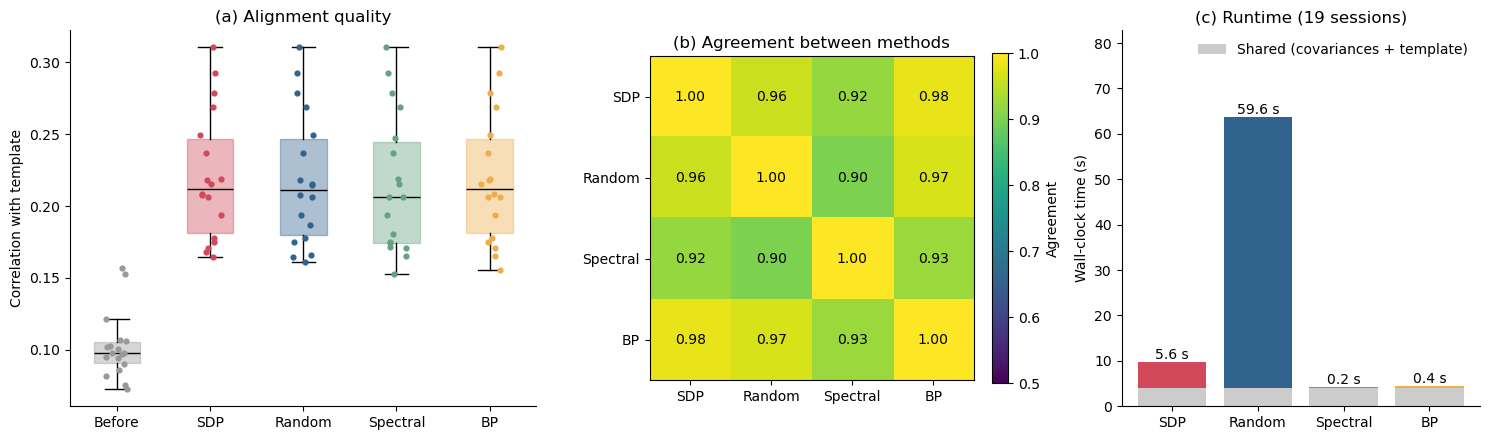

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
rng = np.random.default_rng(0)  # for jittering the points

# (a) Alignment quality before and after sign-flipping
ax = axes[0]
labels = ["Before"] + [LABELS[m] for m in DISPLAY]
values = [before] + [after[m] for m in DISPLAY]
colors = ["0.6"] + [COLORS[m] for m in DISPLAY]
box = ax.boxplot(values, widths=0.5, patch_artist=True, showfliers=False,
                 medianprops={"color": "k"})
for patch, color in zip(box["boxes"], colors):
    patch.set(facecolor=color, alpha=0.4, edgecolor=color)
for i, (v, color) in enumerate(zip(values, colors), start=1):
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=12, color=color, zorder=3)
ax.set_xticks(range(1, len(labels) + 1), labels)
ax.set_ylabel("Correlation with template")
ax.set_title("(a) Alignment quality")

# (b) Pairwise agreement between the methods' flip decisions
ax = axes[1]
agreement = np.array([
    [np.mean(results[m1]["flips"][keep] == results[m2]["flips"][keep]) for m2 in DISPLAY]
    for m1 in DISPLAY
])
im = ax.imshow(agreement, vmin=0.5, vmax=1, cmap="viridis")
for i in range(len(DISPLAY)):
    for j in range(len(DISPLAY)):
        ax.text(j, i, f"{agreement[i, j]:.2f}", ha="center", va="center",
                color="k" if agreement[i, j] > 0.8 else "w")
ax.set_xticks(range(len(DISPLAY)), [LABELS[m] for m in DISPLAY])
ax.set_yticks(range(len(DISPLAY)), [LABELS[m] for m in DISPLAY])
fig.colorbar(im, ax=ax, fraction=0.046, label="Agreement")
ax.set_title("(b) Agreement between methods")

# (c) Runtime
ax = axes[2]
runtimes = np.array([results[m]["runtime"] for m in DISPLAY])
method_times = np.maximum(runtimes - shared, 0)
names = [LABELS[m] for m in DISPLAY]
ax.bar(names, shared, color="0.8", label="Shared (covariances + template)")
ax.bar(names, method_times, bottom=shared, color=[COLORS[m] for m in DISPLAY])
for i, (r, mt) in enumerate(zip(runtimes, method_times)):
    ax.text(i, r, f"{mt:.1f} s", ha="center", va="bottom")
ax.set_ylim(0, runtimes.max() * 1.3)  # leave room for the legend
ax.set_ylabel("Wall-clock time (s)")
ax.legend(frameon=False, loc="upper right")
ax.set_title(f"(c) Runtime ({len(sessions)} sessions)")

for ax in axes[[0, 2]]:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

In line with the paper:

- **(a)** All four methods substantially increase the correlation with the template, with SDP performing as well as
  or better than the others.
- **(b)** The methods largely agree on which parcels to flip.
- **(c)** SDP, spectral synchronisation, and belief propagation are much faster than random search. The numbers
  above the bars give the time taken by each method itself, excluding the shared step (grey).

Note that runtimes depend on your hardware and on `n_jobs`. `random` and `sdp` are seeded via `random_state`, so
their results are reproducible across runs; `spectral` and `belief_propagation` involve no randomness.

## Summary

- `align_signs()` aligns the signs of a list of arrays, while `io.sign_flip_files()` does the same for `.fif`
  files and saves the sign-flipped data. Both give identical results.
- The method is chosen with `method=`, and its hyperparameters are passed as keyword arguments.
- SDP (the default) gives equally good or better alignment than random search at a fraction of the runtime.

Since sign-flipping relies on covariances, it cannot distinguish a flip vector from its global negation;
`osl-signflip` fixes this global sign by convention (see the README).